# Práctica 5 - Análisis Exploratorio de Datos (EDA)

**Sesión 5 - Exploración de datos**    
**Herramientas:** Python, pandas y Matplotlib  
**Dataset:** `clientes_ecommerce.csv`

## Objetivos

En esta práctica aprenderás a:

- realizar un análisis exploratorio de un dataset
- estudiar distribuciones numéricas y categóricas
- interpretar media, mediana, cuartiles y desviación estándar
- utilizar histogramas, gráficos de barras, boxplots y diagramas de dispersión
- detectar posibles valores atípicos mediante el IQR
- estudiar relaciones entre variables
- calcular e interpretar correlaciones
- comparar grupos mediante `groupby()` y `crosstab()`
- diferenciar asociación y causalidad
- comunicar hallazgos respaldados por evidencia

> **Importante:** no basta con generar resultados o gráficos. Cada análisis debe ir acompañado de una **interpretación**

## Preparación

Coloca `clientes_ecommerce.csv` en la misma carpeta que este notebook.

Importa NumPy, pandas y Matplotlib y carga el dataset en un DataFrame llamado `df`

In [1]:
# TODO: importa numpy, pandas y matplotlib.pyplot

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TODO: carga clientes_ecommerce.csv en un DataFrame llamado df

df = pd.read_csv('clientes_ecommerce.csv')

# Parte 1 - Inspección inicial

## Ejercicio 1

Realiza una inspección inicial:

1. Muestra las primeras 10 filas.
2. Consulta las dimensiones.
3. Muestra los nombres de las columnas.
4. Consulta los tipos de datos.
5. Utiliza `info()`.

In [2]:
# TODO: muestra las primeras 10 filas

df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


In [3]:
# TODO: consulta las dimensiones

df.shape

(400, 12)

In [4]:
# TODO: muestra los nombres de las columnas

for c in df.columns:
    print(c)


cliente_id
edad
antiguedad_meses
ingresos_anuales
gasto_mensual
num_compras
devoluciones
dispositivo
zona
nivel_fidelidad
satisfaccion
compra_proximo_mes


In [5]:
# TODO: consulta los tipos de datos

print(df.dtypes)

for columna,tipo in df.dtypes.items():
    print(f"{columna}: {tipo}")

cliente_id              int64
edad                    int64
antiguedad_meses      float64
ingresos_anuales      float64
gasto_mensual         float64
num_compras             int64
devoluciones            int64
dispositivo               str
zona                      str
nivel_fidelidad           str
satisfaccion            int64
compra_proximo_mes        str
dtype: object
cliente_id: int64
edad: int64
antiguedad_meses: float64
ingresos_anuales: float64
gasto_mensual: float64
num_compras: int64
devoluciones: int64
dispositivo: str
zona: str
nivel_fidelidad: str
satisfaccion: int64
compra_proximo_mes: str


In [6]:
# TODO: utiliza info()

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 45.1 KB


### Responde

1. ¿Cuántas muestras contiene?
2. ¿Cuántas columnas?
3. ¿Cuál es la unidad de observación?
4. ¿Cuál es el identificador?
5. ¿Cuál es el target?
6. ¿Qué columnas tienen valores ausentes?

**Respuesta:**
1. Contiene **400** muestras.
2. Tiene **12** columnas.
3. La unidad de observación es el **cliente**.
4. El identificador es `cliente_id`.
5. El target es `compra_proximo_mes`.
6. Tienen ausentes: `antiguedad_meses` (5), `ingresos_anuales` (4) y `gasto_mensual` (3).


# Parte 2 - Exploración de una variable numérica

Vamos a estudiar `gasto_mensual`.

## Ejercicio 2 - Estadística descriptiva

Obtén el número de valores, media, mediana, desviación estándar, mínimo, \(Q_1\), \(Q_2\), \(Q_3\) y máximo.

In [7]:
# TODO: muestra describe() para gasto_mensual


#muestra el dato del gasto mensual de count, si quito count aparece todos los datos de gasto mensual
print(df['gasto_mensual'].describe()) #['count'])
print("Mediana: ", df['gasto_mensual'].median())
print("Q1: ",df['gasto_mensual'].quantile(.25))
print("Q2: ",df['gasto_mensual'].quantile(.50))
print("Q3: ",df['gasto_mensual'].quantile(.75))

# TODO: calcula las medidas necesarias

print("MEDIA: ", df['gasto_mensual'].mean())

count    397.000000
mean      69.089320
std       39.023238
min        5.770000
25%       39.720000
50%       61.170000
75%       90.150000
max      260.000000
Name: gasto_mensual, dtype: float64
Mediana:  61.17
Q1:  39.72
Q2:  61.17
Q3:  90.15
MEDIA:  69.08931989924433


### Completa

| Medida | Valor |
|---|---:|
| Número de valores | 397 |
| Media | 69.09 |
| Mediana | 61.17 |
| Desviación estándar | 39.02 |
| Mínimo | 5.77 |
| Q1 | 39.72 |
| Q2 | 61.17 |
| Q3 | 90.15 |
| Máximo | 260.00 |

### Interpreta

1. ¿Coinciden exactamente media y mediana?
2. ¿Cuál es mayor?
3. ¿Qué puede indicar esta diferencia sobre la distribución?
4. ¿Entre qué valores se encuentra aproximadamente el 50 % central?

**Respuesta:**
1. No coinciden exactamente (media ≈ 69.09 y mediana ≈ 61.17).
2. La media es mayor que la mediana.
3. Sugiere una distribución con asimetría positiva (cola hacia gastos altos).
4. El 50 % central está aproximadamente entre Q1=39.72 y Q3=90.15.


# Parte 3 - Visualizar la distribución

## Ejercicio 3 - Histograma

Crea un histograma de `gasto_mensual` utilizando aproximadamente `bins=15`.

Añade título y etiquetas en ambos ejes.

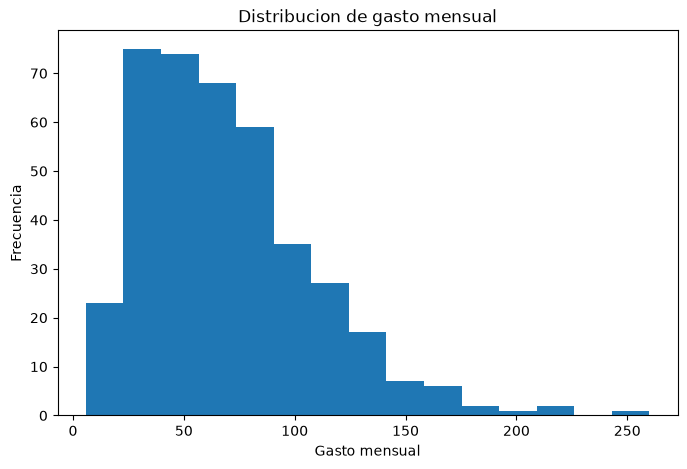

In [8]:
# TODO: crea el histograma de gasto_mensual

plt.figure(figsize=(8,5))
plt.hist(df['gasto_mensual'].dropna(), bins=15) #dropna es para quitar esos valores vacios ("null")
plt.xlabel('Gasto mensual')
plt.ylabel('Frecuencia')
plt.title("Distribucion de gasto mensual")
plt.show()

#en la tabla se visualiza solo los non-null
# este tipo de grafica es asimetria positiva, ocurre cuando la media es mayor que la mediana


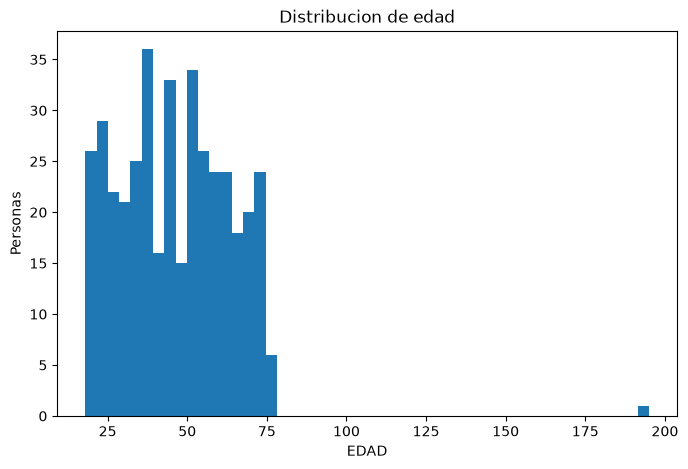

In [9]:
plt.figure(figsize=(8,5))
plt.hist(df['edad'].dropna(), bins=50) #dropna es para quitar esos valores vacios ("null")
plt.xlabel('EDAD')
plt.ylabel('Personas')
plt.title("Distribucion de edad")
plt.show()


### Interpreta

1. ¿Dónde parece concentrarse la mayoría de los clientes?
2. ¿La distribución parece aproximadamente simétrica?
3. ¿Existe una cola hacia valores altos o bajos?
4. ¿Observas valores alejados del resto?

**Respuesta:**
1. La mayoría se concentra en gastos medios-bajos, alrededor de 40–90 €.
2. No es simétrica: hay más masa a la izquierda.
3. Hay una cola hacia valores altos.
4. Sí, se observan valores alejados (gastos muy altos, cerca de 200–260 €).


# Parte 4 - Boxplot y valores atípicos

## Ejercicio 4

Representa `gasto_mensual` mediante un boxplot. Trata adecuadamente los valores ausentes.

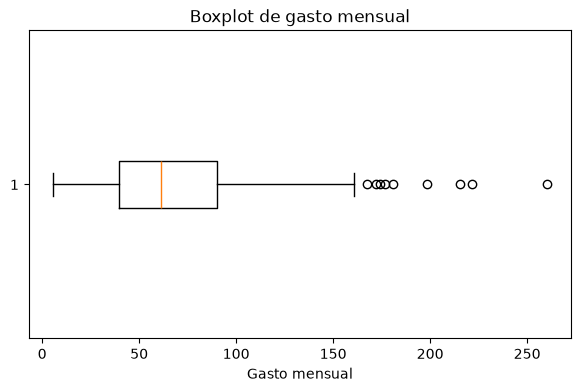

In [10]:
# TODO: crea un boxplot de gasto_mensual

#boxplot nos ensena los valores atipicos

plt.figure(figsize=(7,4))
plt.boxplot(df['gasto_mensual'].dropna(), orientation='horizontal')
plt.xlabel('Gasto mensual')
plt.title('Boxplot de gasto mensual')
plt.show()


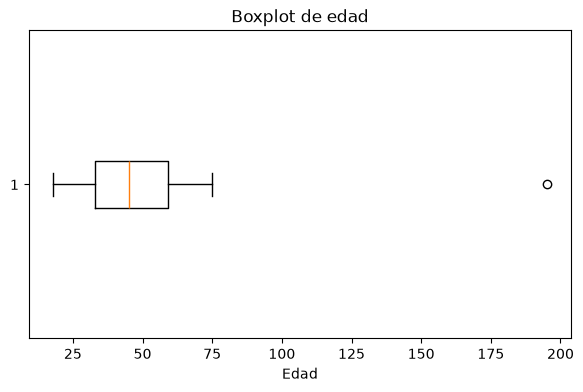

In [11]:
plt.figure(figsize=(7,4))
plt.boxplot(df['edad'].dropna(), orientation='horizontal')
plt.xlabel('Edad')
plt.title('Boxplot de edad')
plt.show()


### Interpreta

1. ¿Dónde se encuentra aproximadamente la mediana?
2. ¿Observas posibles outliers?
3. ¿Aparecen principalmente por encima o por debajo?
4. ¿Podemos afirmar que esos valores son errores únicamente observando el boxplot? Justifica.

**Respuesta:**
1. La mediana está alrededor de 61 €.
2. Sí, hay posibles outliers.
3. Aparecen principalmente por encima (gastos altos).
4. No. El boxplot solo señala valores extremos según el IQR; pueden ser clientes reales con mucho gasto, no necesariamente errores.


# Parte 5 - Detectar outliers mediante IQR

## Ejercicio 5

Calcula:

$$
IQR=Q_3-Q_1
$$

y:

$$
L_{inferior}=Q_1-1.5IQR
$$

$$
L_{superior}=Q_3+1.5IQR
$$

Después localiza los clientes cuyo `gasto_mensual` esté fuera de estos límites y guarda el resultado en `outliers_gasto`.

In [12]:
# TODO: calcula Q1, Q3 e IQR

Q1 = df['gasto_mensual'].quantile(.25)
Q2 = df['gasto_mensual'].quantile(.50)
Q3 = df['gasto_mensual'].quantile(.75)

#RANGO INTERCUANTILICO

IQR = Q3 - Q1

# TODO: calcula los límites inferior y superior

Linf = Q1 - 1.5*IQR
Lsup = Q3 + 1.5*IQR

# TODO: muestra los resultados

print(f"IQR: {IQR:.2f}, Linferior: {Linf:.2f}, Lsuperior: {Lsup:.2f}")

IQR: 50.43, Linferior: -35.93, Lsuperior: 165.80


In [13]:
# TODO: calcula Q1, Q3 e IQR EDADES

Q1_edad = df['edad'].quantile(.25)
Q2_edad = df['edad'].quantile(.50)
Q3_edad = df['edad'].quantile(.75)

#RANGO INTERCUANTILICO

IQR = Q3_edad - Q1_edad

# TODO: calcula los límites inferior y superior

Linfedad = Q1_edad - 1.5*IQR
Lsupedad = Q3_edad + 1.5*IQR

# TODO: muestra los resultados

print(f"IQR: {IQR:.2f}, Linferior: {Linfedad:.2f}, Lsuperior: {Lsupedad:.2f}")

IQR: 26.00, Linferior: -6.00, Lsuperior: 98.00


In [14]:
# TODO: crea outliers_gasto

filtro = (df['gasto_mensual'] < Linf) | (df['gasto_mensual'] > Lsup) # | es un OR
outliers_gasto = df[filtro]

# TODO: muestra los posibles outliers

outliers_gasto


,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
50,20051,75,49.0,22908.36,176.52,3,1,Móvil,Este,Oro,3,Sí
68,20069,29,78.0,33382.86,215.30,8,2,Móvil,Centro,Bronce,4,No
202,20203,45,57.0,24727.71,167.26,7,4,Móvil,Norte,Platino,1,Sí
203,20204,25,41.0,39329.38,173.91,6,0,Ordenador,Norte,Bronce,2,Sí
207,20208,41,65.0,25812.18,221.59,10,0,Ordenador,Centro,Plata,5,Sí
268,20269,21,61.0,34737.20,198.28,7,2,Tablet,Centro,Bronce,3,Sí
292,20293,20,94.0,31714.55,172.31,13,0,Tablet,Este,Bronce,3,Sí
318,20319,56,38.0,9000.00,180.60,4,0,Ordenador,Este,Bronce,2,Sí
398,20399,75,85.0,40391.73,260.00,10,1,Móvil,Oeste,Bronce,4,Sí


In [15]:
# TODO: crea outliers_edad

filtro = (df['edad'] < Linfedad) | (df['edad'] > Lsupedad) # | es un OR
outliers_edad = df[filtro]

# TODO: muestra los posibles outliers

outliers_edad


,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
137,20138,195,106.0,32593.41,138.99,6,0,Móvil,Este,Plata,3,No


### Responde

1. ¿Cuántos posibles outliers has encontrado?
2. ¿Qué porcentaje representan?
3. ¿Cuál es el mayor `gasto_mensual`?
4. ¿Eliminarías automáticamente estas observaciones?
5. ¿Qué investigarías antes?

**Respuesta:**
1. He encontrado 9 posibles outliers de gasto.
2. Representan un 2,25 % de las 400 muestras.
3. El mayor gasto_mensual es 260.
4. No los eliminaría automáticamente.
5. Investigaría si son errores de registro, clientes VIP reales, o si afectan mucho al análisis; también revisaría el resto de variables de esas filas.


# Parte 6 - Comparar varias distribuciones

## Ejercicio 6

Analiza:

- `edad`
- `ingresos_anuales`
- `gasto_mensual`
- `num_compras`
- `devoluciones`

Consulta sus estadísticas descriptivas y crea un histograma independiente para cada variable.

In [16]:
# TODO: consulta las estadisticas descriptivas de las variables indicadas

print(df[['edad', 'ingresos_anuales', 'gasto_mensual', 'num_compras', 'devoluciones']].describe())


             edad  ingresos_anuales  gasto_mensual  num_compras  devoluciones
count  400.000000        396.000000     397.000000   400.000000    400.000000
mean    46.402500      36440.920379      69.089320     8.225000      1.225000
std     18.007809      14325.228166      39.023238     2.780955      1.136929
min     18.000000       9000.000000       5.770000     2.000000      0.000000
25%     33.000000      26034.092500      39.720000     6.000000      0.000000
50%     45.000000      36817.275000      61.170000     8.000000      1.000000
75%     59.000000      45969.032500      90.150000    10.000000      2.000000
max    195.000000      82925.370000     260.000000    17.000000      5.000000


In [17]:
# TODO: calcula sus medianas

print(df[['edad', 'ingresos_anuales', 'gasto_mensual', 'num_compras', 'devoluciones']].median())


edad                   45.000
ingresos_anuales    36817.275
gasto_mensual          61.170
num_compras             8.000
devoluciones            1.000
dtype: float64


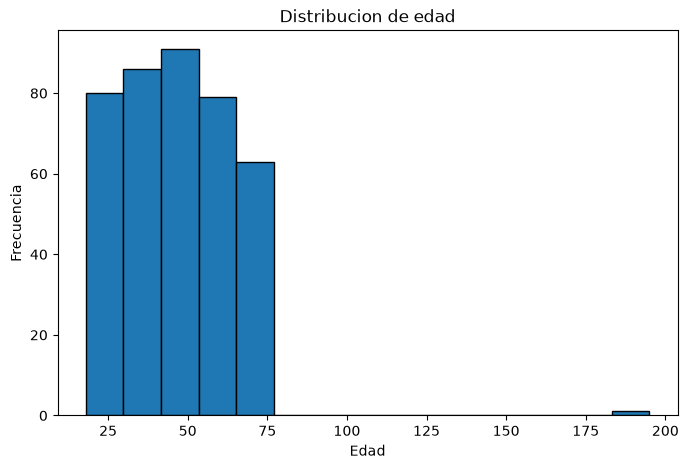

In [18]:
# TODO: histograma de edad

plt.figure(figsize=(8,5))
plt.hist(df['edad'].dropna(), bins=15, edgecolor='black')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.title('Distribucion de edad')
plt.show()


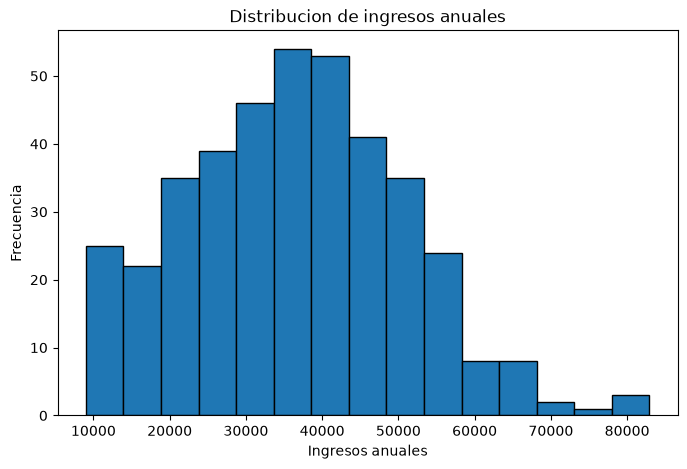

In [19]:
# TODO: histograma de ingresos_anuales

plt.figure(figsize=(8,5))
plt.hist(df['ingresos_anuales'].dropna(), bins=15, edgecolor='black')
plt.xlabel('Ingresos anuales')
plt.ylabel('Frecuencia')
plt.title('Distribucion de ingresos anuales')
plt.show()


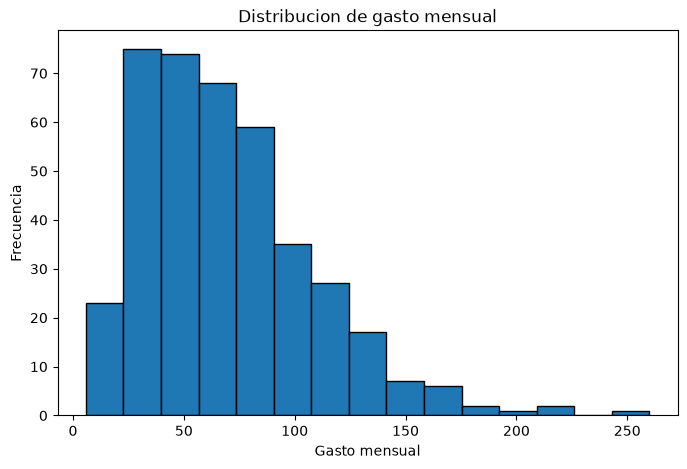

In [20]:
# TODO: histograma de gasto_mensual

plt.figure(figsize=(8,5))
plt.hist(df['gasto_mensual'].dropna(), bins=15, edgecolor='black')
plt.xlabel('Gasto mensual')
plt.ylabel('Frecuencia')
plt.title('Distribucion de gasto mensual')
plt.show()


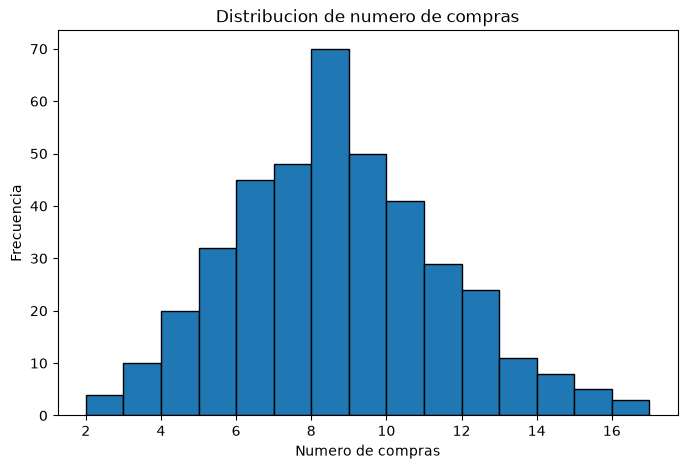

In [21]:
# TODO: histograma de num_compras

plt.figure(figsize=(8,5))
plt.hist(df['num_compras'].dropna(), bins=15, edgecolor='black')
plt.xlabel('Numero de compras')
plt.ylabel('Frecuencia')
plt.title('Distribucion de numero de compras')
plt.show()


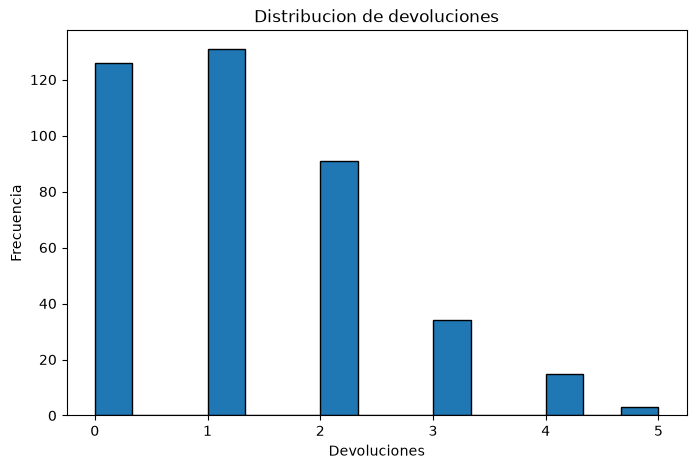

In [22]:
# TODO: histograma de devoluciones

plt.figure(figsize=(8,5))
plt.hist(df['devoluciones'].dropna(), bins=15, edgecolor='black')
plt.xlabel('Devoluciones')
plt.ylabel('Frecuencia')
plt.title('Distribucion de devoluciones')
plt.show()


### Completa

| Variable | Media | Mediana | Mínimo | Máximo | Observación relevante |
|---|---:|---:|---:|---:|---|
| edad | 46.40 | 45.00 | 18 | 195 | Máximo irreal (195 años) |
| ingresos_anuales | 36440.92 | 36817.28 | 9000 | 82925.37 | Media ≈ mediana |
| gasto_mensual | 69.09 | 61.17 | 5.77 | 260 | Asimetría positiva |
| num_compras | 8.23 | 8.00 | 2 | 17 | Centrada alrededor de 8 |
| devoluciones | 1.23 | 1.00 | 0 | 5 | La mayoría tiene pocas |

### Busca una observación sospechosa

- ¿Qué variable es?
- ¿Qué valor tiene?
- ¿Por qué parece sospechoso?
- ¿Es un outlier?
- ¿Podemos afirmar directamente que es un error?
- ¿Qué harías antes de modificarlo?

**Respuesta:**
- Variable: edad.
- Valor: 195.
- Parece sospechoso porque una edad de 195 años no es realista.
- Sí, también es outlier por el criterio IQR.
- No podemos afirmar al 100 % solo con eso, pero es muy probable un error.
- Antes de modificarlo comprobaría esa fila, posibles fallos de carga y si hay más edades imposibles.


# Parte 7 - Variables categóricas

## Ejercicio 7 - Frecuencias

Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes`.

Calcula frecuencias absolutas, relativas y porcentajes mediante `value_counts()`.

In [23]:
# TODO: analiza dispositivo

print(df['dispositivo'].value_counts())
print(df['dispositivo'].value_counts(normalize=True)*100) # hace que los datos pasen a porcentajes

dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64
dispositivo
Móvil        60.50
Ordenador    33.25
Tablet        6.25
Name: proportion, dtype: float64


In [24]:
# TODO: analiza zona

print(df['zona'].value_counts())
print(df['zona'].value_counts(normalize=True)*100)

zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64
zona
Este      22.25
Sur       20.00
Norte     19.75
Oeste     19.00
Centro    19.00
Name: proportion, dtype: float64


In [25]:
# TODO: analiza nivel_fidelidad

print(df['nivel_fidelidad'].value_counts())
print(df['nivel_fidelidad'].value_counts(normalize=True)*100)

nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64
nivel_fidelidad
Bronce     40.50
Plata      26.25
Oro        20.75
Platino    12.50
Name: proportion, dtype: float64


In [26]:
# TODO: analiza compra_proximo_mes

print(df['compra_proximo_mes'].value_counts())
print(df['compra_proximo_mes'].value_counts(normalize=True)*100)

compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64
compra_proximo_mes
No    61.5
Sí    38.5
Name: proportion, dtype: float64


### Completa

| Variable | Categoría más frecuente | Nº muestras | Porcentaje |
|---|---|---:|---:|
| dispositivo | Móvil | 242 | 60.5% |
| zona | Este | 89 | 22.2% |
| nivel_fidelidad | Bronce | 162 | 40.5% |
| compra_proximo_mes | No | 246 | 61.5% |


# Parte 8 - Visualización de variables categóricas

## Ejercicio 8

Crea gráficos de barras independientes para:

- `dispositivo`
- `nivel_fidelidad`
- `compra_proximo_mes`

Todos deben incluir título y etiquetas.

Index(['Móvil', 'Ordenador', 'Tablet'], dtype='str', name='dispositivo')
[242 133  25]


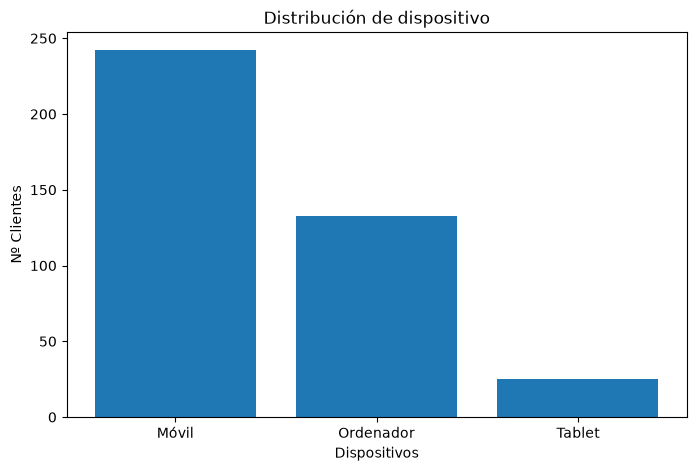

In [27]:
# TODO: gráfico de barras de dispositivo

conteos_disp = df['dispositivo'].value_counts()
print(conteos_disp.index)
print(conteos_disp.values)

plt.figure(figsize=(8,5))
plt.bar(conteos_disp.index, conteos_disp.values)
plt.xlabel('Dispositivos')
plt.ylabel('Nº Clientes')
plt.title('Distribución de dispositivo')
plt.show()

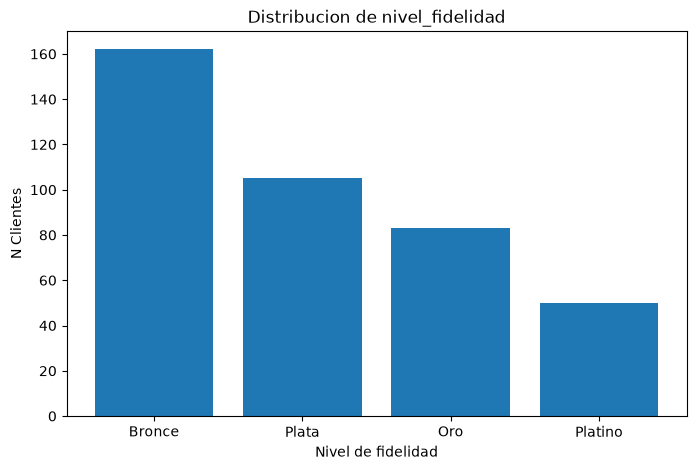

In [28]:
# TODO: grafico de barras de nivel_fidelidad

conteos_fid = df['nivel_fidelidad'].value_counts()

plt.figure(figsize=(8,5))
plt.bar(conteos_fid.index, conteos_fid.values)
plt.xlabel('Nivel de fidelidad')
plt.ylabel('N Clientes')
plt.title('Distribucion de nivel_fidelidad')
plt.show()


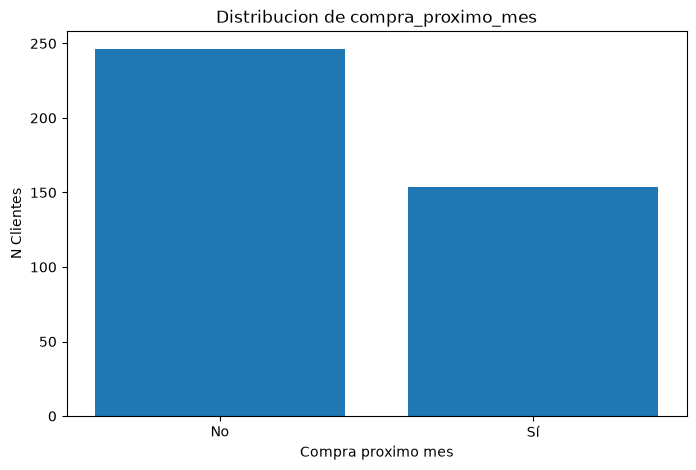

In [29]:
# TODO: grafico de barras de compra_proximo_mes

conteos_compra = df['compra_proximo_mes'].value_counts()

plt.figure(figsize=(8,5))
plt.bar(conteos_compra.index, conteos_compra.values)
plt.xlabel('Compra proximo mes')
plt.ylabel('N Clientes')
plt.title('Distribucion de compra_proximo_mes')
plt.show()


### Interpreta

Escribe al menos una conclusión sobre cada gráfico.

Para `compra_proximo_mes`, responde además:

> ¿Las clases están perfectamente equilibradas?

Justifica utilizando porcentajes.

**Respuesta:**
- **dispositivo:** Predomina **Móvil** (~60,5 %); Tablet es minoritaria.
- **nivel_fidelidad:** Hay más clientes **Bronce**; Platino es el menos frecuente.
- **compra_proximo_mes:** Predomina la clase **No**.

¿Están equilibradas? No. Aproximadamente 61,5 % No frente a 38,5 % Sí.


# Parte 9 - Relación entre dos variables numéricas

Queremos investigar:

> **¿Existe alguna relación entre el número de compras realizadas y el gasto mensual?**

## Ejercicio 9 - Scatter plot

Representa:

$$
X=\text{num\_compras}
$$

$$
Y=\text{gasto\_mensual}
$$

mediante un diagrama de dispersión.

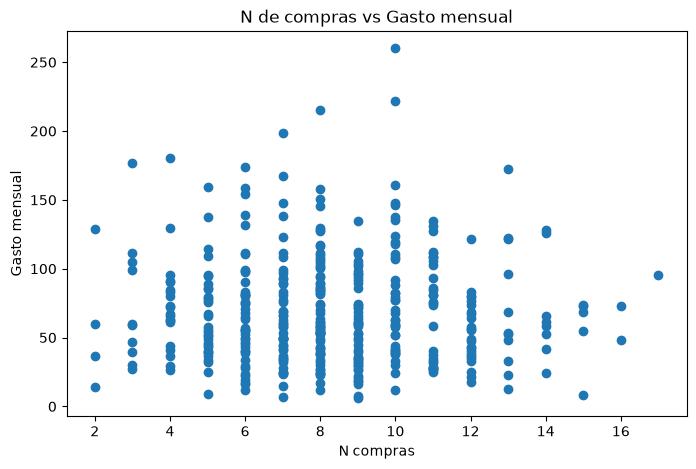

In [30]:
# TODO: crea un scatter plot de num_compras frente a gasto_mensual

plt.figure(figsize=(8,5))
plt.scatter(df['num_compras'], df['gasto_mensual'])
plt.xlabel('N compras')
plt.ylabel('Gasto mensual')
plt.title('N de compras vs Gasto mensual')
plt.show()


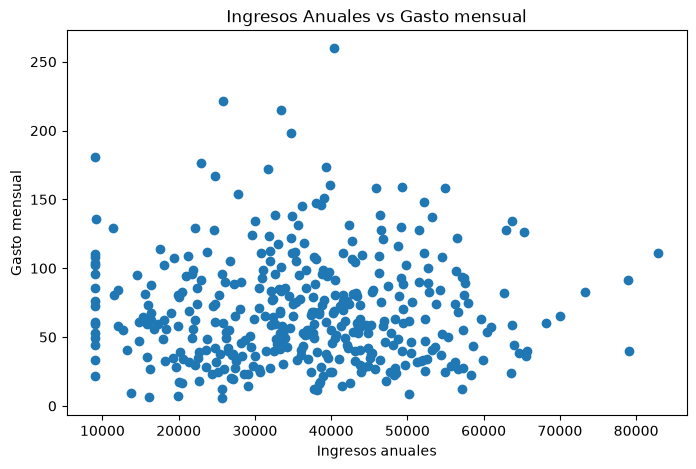

In [31]:
plt.figure(figsize=(8,5))
plt.scatter(df['ingresos_anuales'], df['gasto_mensual'])
plt.xlabel('Ingresos anuales')
plt.ylabel('Gasto mensual')
plt.title('Ingresos Anuales vs Gasto mensual')
plt.show()


### Antes de calcular la correlación

1. ¿Parece existir una relación?
2. ¿Parece positiva o negativa?
3. ¿Parece fuerte o débil?
4. ¿Observas muestras especialmente alejadas?

**Respuesta:**
1. A simple vista apenas se ve una relación clara.
2. No se aprecia una tendencia positiva ni negativa clara.
3. Parece muy débil o nula.
4. Sí, hay puntos con gasto muy alto separados del resto.


# Parte 10 - Correlación

## Ejercicio 10

Calcula la correlación entre `num_compras` y `gasto_mensual` utilizando `corr()`.

In [32]:
# TODO: calcula la correlación entre num_compras y gasto_mensual

print(df['num_compras'].corr(df['gasto_mensual']))
print(df['num_compras'].corr(df['num_compras']))

#  0 - No hay correlacion, cuanto mas cerca al 0 menos correlacion
# -1 - Correlacion negativa
# +1 - Correlacion positiva

-0.014165499001183279
1.0


### Interpreta

1. ¿Cuál es el valor de \(r\)?
2. ¿Es positivo o negativo?
3. ¿Qué significa el signo?
4. ¿Coincide con lo observado en el scatter plot?
5. ¿Podemos afirmar que realizar más compras **provoca** un mayor gasto mensual? Justifica.

**Respuesta:**
1. \(r \approx -0.014\).
2. Es ligeramente negativo, casi cero.
3. El signo negativo indicaría que al subir una variable la otra baja, pero aquí el valor es tan pequeño que la relación es prácticamente nula.
4. Sí, coincide con el scatter: no se ve una nube con pendiente clara.
5. No. Correlación (y aquí casi no hay) no implica causalidad; además la asociación es insignificante.


# Parte 11 - Matriz de correlaciones

## Ejercicio 11

Selecciona las variables numéricas y calcula su matriz de correlaciones.

> **Atención:** `cliente_id` es técnicamente numérico, pero conceptualmente es un identificador. No debes incluirlo.

In [33]:
# TODO: selecciona las variables numericas excluyendo cliente_id

num_vars = df.select_dtypes(include='number').drop(columns=['cliente_id'])

# TODO: calcula y muestra la matriz de correlaciones

matriz_corr = num_vars.corr()
matriz_corr


,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,satisfaccion
edad,1.000000,0.031192,-0.036610,0.021361,-0.077583,-0.097102,-0.062801
antiguedad_meses,0.031192,1.000000,-0.058738,0.006482,-0.099965,-0.056458,-0.040051
ingresos_anuales,-0.036610,-0.058738,1.000000,-0.000367,0.072991,0.000260,-0.062595
gasto_mensual,0.021361,0.006482,-0.000367,1.000000,-0.014165,0.030674,-0.054523
num_compras,-0.077583,-0.099965,0.072991,-0.014165,1.000000,-0.005747,0.092211
devoluciones,-0.097102,-0.056458,0.000260,0.030674,-0.005747,1.000000,0.030817
satisfaccion,-0.062801,-0.040051,-0.062595,-0.054523,0.092211,0.030817,1.000000


### Interpreta

1. ¿Por qué todos los valores de la diagonal son 1?
2. ¿Por qué la matriz es simétrica?
3. Sin considerar la diagonal, ¿qué pareja presenta la correlación positiva más alta?
4. ¿Qué pareja presenta la correlación más negativa?
5. ¿Hay variables cuya correlación sea prácticamente cero?

**Respuesta:**
1. Porque cada variable correlaciona perfectamente consigo misma.
2. Porque \(corr(A,B)=corr(B,A)\).
3. La más alta positiva es **num_compras–satisfaccion** (≈ 0.09).
4. La más negativa es **antiguedad_meses–num_compras** (≈ -0.10).
5. Sí, por ejemplo **ingresos_anuales–gasto_mensual** ≈ 0 y **gasto_mensual–num_compras** ≈ 0.


# Parte 12 - Visualizar las correlaciones

## Ejercicio 12

Representa la matriz mediante `plt.imshow()`.

Añade nombres de variables en ambos ejes, barra de color y título.

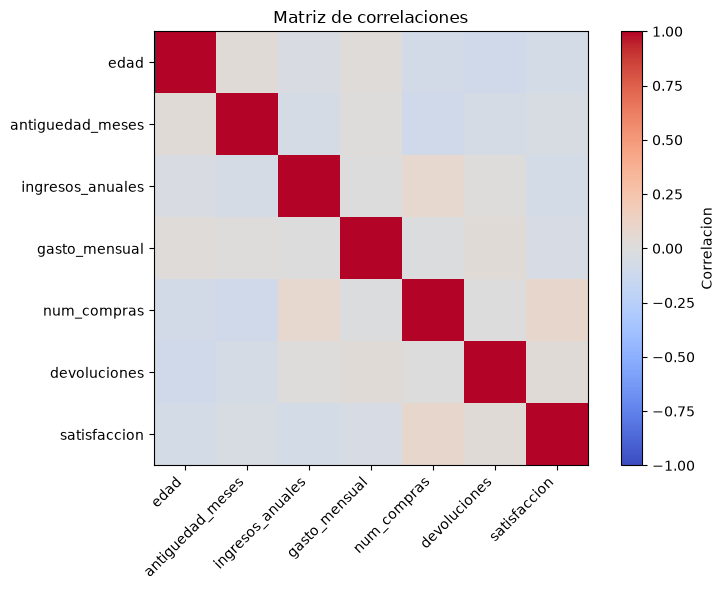

In [34]:
# TODO: representa la matriz de correlaciones con plt.imshow()

plt.figure(figsize=(8,6))
plt.imshow(matriz_corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlacion')
plt.xticks(range(len(matriz_corr.columns)), matriz_corr.columns, rotation=45, ha='right')
plt.yticks(range(len(matriz_corr.columns)), matriz_corr.columns)
plt.title('Matriz de correlaciones')
plt.tight_layout()
plt.show()


### Interpreta tres relaciones

Selecciona tres relaciones de la matriz y explica qué significa cada valor.

1. **num_compras y satisfaccion (≈ 0.09):** correlación positiva débil; quien compra más tiende ligeramente a estar más satisfecho, pero la relación es pequeña.
2. **antiguedad_meses y num_compras (≈ -0.10):** correlación negativa débil; los más antiguos no necesariamente compran más en el último año.
3. **ingresos_anuales y gasto_mensual (≈ 0.00):** prácticamente no hay correlación lineal entre ingresos y gasto mensual.

Recuerda:

$$
\boxed{\text{correlación}\neq\text{causalidad}}
$$


# Parte 13 - Variable numérica frente a categórica

Queremos investigar:

> **¿Los clientes que realizan una compra el mes siguiente presentan un gasto histórico diferente?**

## Ejercicio 13

Utiliza `groupby()` para obtener para cada valor de `compra_proximo_mes`:

- número de clientes
- gasto medio
- mediana
- desviación estándar.

In [46]:
# TODO: agrupa por compra_proximo_mes y calcula las estadisticas solicitadas

df.groupby('compra_proximo_mes')['gasto_mensual'].agg(['count', 'mean', 'median', 'std'])


,count,mean,median,std
compra_proximo_mes,,,,
No,245,64.589469,59.28,33.693480
Sí,152,76.342368,66.50,45.534042


In [48]:
# TODO: agrupa por compra_proximo_mes y calcula las estadisticas solicitadas

df.groupby('compra_proximo_mes')['ingresos_anuales'].agg(['count', 'mean', 'median', 'std'])


,count,mean,median,std
compra_proximo_mes,,,,
No,245,36457.790449,36999.62,13983.264281
Sí,151,36413.548411,36715.09,14910.598296


### Interpreta

1. ¿Qué grupo presenta mayor gasto medio?
2. ¿Y mayor mediana?
3. ¿Las diferencias parecen grandes o pequeñas?
4. ¿La media y la mediana cuentan exactamente la misma historia?

**Respuesta:**
1. El grupo **Sí** tiene mayor gasto medio (~76.3 frente a ~64.6).
2. También el grupo **Sí** tiene mayor mediana (~66.5 frente a ~59.3).
3. La diferencia es **moderada** (unos 10–12 €), no enorme.
4. Cuentan una historia **parecida** (Sí gasta más), pero la media está más afectada por valores altos que la mediana.


# Parte 14 - Comparación visual entre grupos

## Ejercicio 14

Crea:

- `grupo_no`: gasto mensual de quienes no compran el mes siguiente
- `grupo_si`: gasto mensual de quienes sí compran.

Representa ambos mediante un único boxplot.

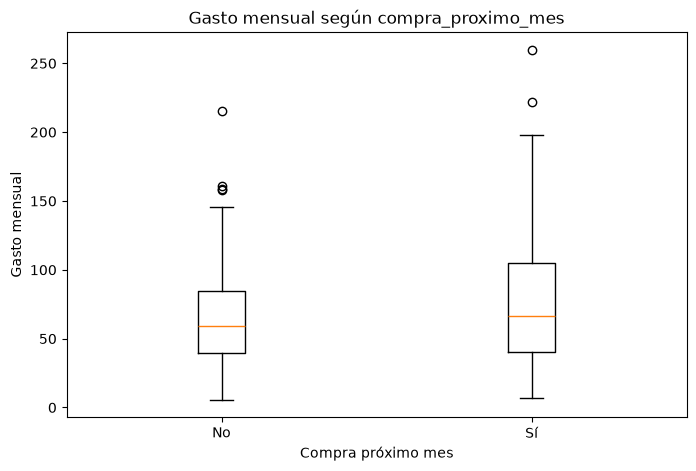

In [57]:
# TODO: crea grupo_no y grupo_si

grupo_no = df.loc[df['compra_proximo_mes'] == 'No', 'gasto_mensual'].dropna()

grupo_si = df.loc[df['compra_proximo_mes'] == 'Sí', 'gasto_mensual'].dropna()

# TODO: representa ambos grupos mediante un boxplot

plt.figure(figsize=(8,5))
plt.boxplot([grupo_no, grupo_si], tick_labels= {'No','Sí'})
plt.xlabel('Compra próximo mes')
plt.ylabel('Gasto mensual')
plt.title('Gasto mensual según compra_proximo_mes')
plt.show()


### Interpreta

1. ¿Qué grupo presenta una mediana mayor?
2. ¿Cuál parece tener mayor dispersión?
3. ¿Existen outliers en ambos?
4. ¿El gráfico apoya las conclusiones obtenidas mediante `groupby()`?

**Respuesta:**
1. El grupo **Sí** tiene mediana mayor.
2. El grupo **Sí** parece tener **mayor dispersión** (std y caja más amplias).
3. Sí, hay outliers (gastos altos) en ambos grupos.
4. **Sí**, apoya el groupby(): quienes compran el mes siguiente tienden a gastar algo más.


# Parte 15 - Dos variables categóricas

Queremos responder:

> **¿La proporción de compra es igual para todos los niveles de fidelidad?**

## Ejercicio 15

Crea:

1. una tabla de contingencia con frecuencias absolutas
2. una tabla normalizada por filas mediante `normalize="index"`
3. una versión expresada en porcentajes.

In [37]:
# TODO: tabla de contingencia con frecuencias absolutas

tabla_abs = pd.crosstab(df['nivel_fidelidad'], df['compra_proximo_mes'])
tabla_abs


compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,112,50
Oro,52,31
Plata,63,42
Platino,19,31


In [58]:
# TODO: tabla normalizada por filas

frecuencias = pd.crosstab(df['nivel_fidelidad'], df['compra_proximo_mes'], normalize='index')
frecuencias


compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,0.691358,0.308642
Oro,0.626506,0.373494
Plata,0.600000,0.400000
Platino,0.380000,0.620000


In [ ]:
# TODO: muestra las proporciones como porcentajes

frecuencias = tabla_rel * 100
frecuencias.round(2)

(frecuencias*100).round(2)


compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,6913.58,3086.42
Oro,6265.06,3734.94
Plata,6000.00,4000.00
Platino,3800.00,6200.00


### Interpreta

1. ¿Qué nivel tiene mayor número absoluto de clientes que compran?
2. ¿Qué nivel tiene mayor porcentaje de clientes que compran?
3. ¿Coinciden necesariamente ambas respuestas?
4. ¿Por qué son importantes las proporciones cuando los grupos tienen tamaños diferentes?

**Respuesta:**
1. **Bronce** tiene más compras absolutas (50).
2. **Platino** tiene el mayor porcentaje (~62 %).
3. **No** coinciden necesariamente: un grupo grande puede sumar más casos aunque su tasa sea menor.
4. Las proporciones permiten comparar de forma justa grupos de distinto tamaño.


# Parte 16 - Correlación no implica causalidad

## Ejercicio 16 - Razonamiento

Un compañero observa una relación entre `nivel_fidelidad` y `compra_proximo_mes` y afirma:

> **«Subir a un cliente al nivel Platino hará que compre el próximo mes».**

¿Es correcta esta conclusión?

Redacta entre **5 y 8 líneas** utilizando correctamente:

- asociación
- causalidad
- variables adicionales
- evidencia

### Respuesta

No es correcta. En los datos solo vemos una asociación: Platino tiene mayor proporción de compra, pero eso no demuestra causalidad. Puede que los clientes Platino ya fueran más activos o tuvieran más ingresos antes de subir de nivel. Hay variables adicionales (gasto, satisfacción, antigüedad, dispositivo…) que también pueden influir. Para afirmar que “subir a Platino provoca compra” haría falta un experimento o evidencia causal más fuerte, no solo una tabla observada. Por tanto, la conclusión del compañero va más allá de lo que permiten los datos.


# Parte 17 - Investiga una hipótesis

## Ejercicio 17

Elige **una**:

**A.** ¿Los clientes con mayores ingresos gastan más mensualmente?  
**B.** ¿Los clientes más antiguos realizan más compras?  
**C.** ¿La satisfacción está relacionada con el número de compras?  
**D.** ¿El número de devoluciones está relacionado con la satisfacción?

Realiza:

1. selección de variables
2. estadística descriptiva
3. visualización adecuada
4. correlación si procede
5. interpretación.

Estadistica descriptiva:
       ingresos_anuales  gasto_mensual
count        396.000000     397.000000
mean       36440.920379      69.089320
std        14325.228166      39.023238
min         9000.000000       5.770000
25%        26034.092500      39.720000
50%        36817.275000      61.170000
75%        45969.032500      90.150000
max        82925.370000     260.000000

Correlacion:
-0.0003672525505325708


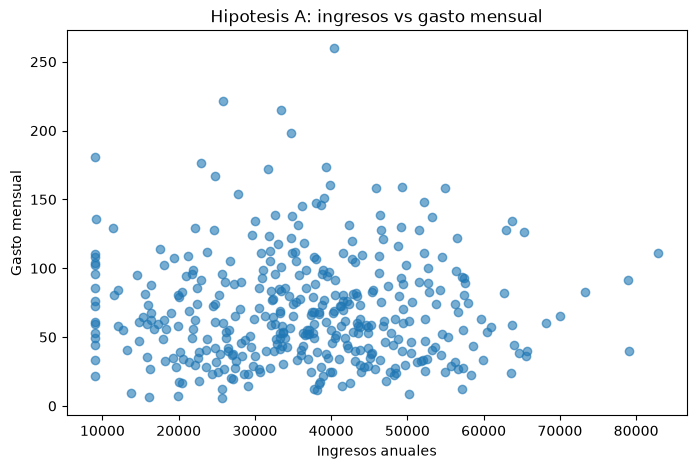

In [40]:
# TODO: desarrolla aqui el analisis de la hipotesis seleccionada

# Hipotesis A: Los clientes con mayores ingresos gastan mas mensualmente?

print('Estadistica descriptiva:')
print(df[['ingresos_anuales', 'gasto_mensual']].describe())

print('\nCorrelacion:')
r = df['ingresos_anuales'].corr(df['gasto_mensual'])
print(r)

plt.figure(figsize=(8,5))
plt.scatter(df['ingresos_anuales'], df['gasto_mensual'], alpha=0.6)
plt.xlabel('Ingresos anuales')
plt.ylabel('Gasto mensual')
plt.title('Hipotesis A: ingresos vs gasto mensual')
plt.show()


### Conclusión de la hipótesis

Redacta entre **5 y 10 líneas**. No escribas únicamente el valor de correlación.

**Respuesta:**
He analizado la hipótesis A (ingresos vs gasto mensual). El diagrama de dispersión no muestra una pendiente clara y la correlación es prácticamente 0. Por tanto, en este dataset no se observa que mayores ingresos impliquen mayor gasto mensual. Puede haber otros factores (hábitos, ofertas, nivel de fidelidad) que expliquen el gasto mejor que los ingresos. Correlación cercana a cero no prueba ausencia total de relación no lineal, pero sí indica que no hay relación lineal relevante. Tampoco podemos hablar de causalidad: solo de lo observado en estos datos.


# Parte 18 - El reto del analista

## Ejercicio 18

Trabaja ahora con mayor autonomía:

> **¿Qué características parecen diferenciar a los clientes que compran el mes siguiente de los que no compran?**

Puedes investigar:

`edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad` y `satisfaccion`.

Tu análisis debe contener como mínimo:

- una comparación numérica
- una comparación categórica
- dos visualizaciones
- estadísticas descriptivas
- una tabla de proporciones.

In [41]:
# TODO: comparacion numerica

vars_num = ['edad', 'antiguedad_meses', 'ingresos_anuales', 'gasto_mensual', 'num_compras', 'devoluciones', 'satisfaccion']
comparacion = df.groupby('compra_proximo_mes')[vars_num].agg(['mean', 'median'])
comparacion


edad        antiguedad_meses        ingresos_anuales  \
                         mean median             mean median             mean   
compra_proximo_mes                                                              
No                  47.813008   47.5        59.469136   59.0     36457.790449   
Sí                  44.149351   44.0        60.460526   60.5     36413.548411   

                             gasto_mensual        num_compras         \
                      median          mean median        mean median   
compra_proximo_mes                                                     
No                  36999.62     64.589469  59.28    8.146341    8.0   
Sí                  36715.09     76.342368  66.50    8.350649    8.0   

                   devoluciones        satisfaccion         
                           mean median         mean median  
compra_proximo_mes                                          
No                     1.288618    1.0     3.284553    3.0  
Sí                     1.123377    1.0     3.402597    3.0

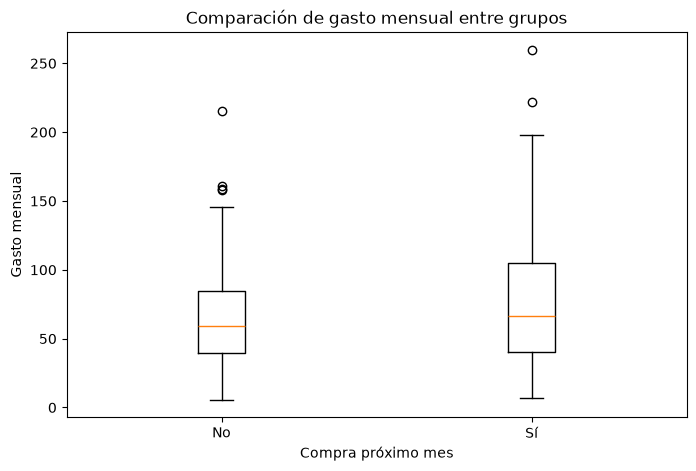

In [42]:
# TODO: primera visualizacion

grupo_no = df.loc[df['compra_proximo_mes'] == 'No', 'gasto_mensual'].dropna()
valor_si = [v for v in df['compra_proximo_mes'].unique() if str(v).startswith('S')][0]
grupo_si = df.loc[df['compra_proximo_mes'] == valor_si, 'gasto_mensual'].dropna()

plt.figure(figsize=(8,5))
plt.boxplot([grupo_no, grupo_si])
plt.xticks([1, 2], ['No', 'Sí'])
plt.xlabel('Compra próximo mes')
plt.ylabel('Gasto mensual')
plt.title('Comparación de gasto mensual entre grupos')
plt.show()


In [43]:
# TODO: comparacion categorica y tabla de proporciones

print('Dispositivo (% por grupo):')
print(pd.crosstab(df['compra_proximo_mes'], df['dispositivo'], normalize='index') * 100)

print('\nNivel de fidelidad (% por grupo):')
print(pd.crosstab(df['compra_proximo_mes'], df['nivel_fidelidad'], normalize='index') * 100)

print('\nProporcion de compra por nivel de fidelidad (%):')
print((pd.crosstab(df['nivel_fidelidad'], df['compra_proximo_mes'], normalize='index') * 100).round(2))


Dispositivo (% por grupo):
dispositivo             Móvil  Ordenador    Tablet
compra_proximo_mes                                
No                  62.195122  31.300813  6.504065
Sí                  57.792208  36.363636  5.844156

Nivel de fidelidad (% por grupo):
nivel_fidelidad        Bronce        Oro      Plata    Platino
compra_proximo_mes                                            
No                  45.528455  21.138211  25.609756   7.723577
Sí                  32.467532  20.129870  27.272727  20.129870

Proporcion de compra por nivel de fidelidad (%):
compra_proximo_mes     No     Sí
nivel_fidelidad                 
Bronce              69.14  30.86
Oro                 62.65  37.35
Plata               60.00  40.00
Platino             38.00  62.00


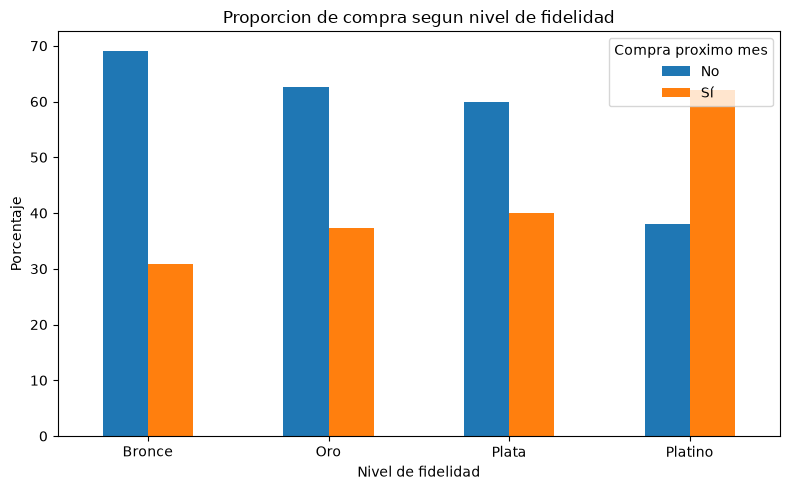

In [44]:
# TODO: segunda visualizacion

pct_fid = pd.crosstab(df['nivel_fidelidad'], df['compra_proximo_mes'], normalize='index') * 100

pct_fid.plot(kind='bar', figsize=(8,5))
plt.xlabel('Nivel de fidelidad')
plt.ylabel('Porcentaje')
plt.title('Proporcion de compra segun nivel de fidelidad')
plt.xticks(rotation=0)
plt.legend(title='Compra proximo mes')
plt.tight_layout()
plt.show()


### Interpretación del reto

Resume qué características parecen diferenciar a ambos grupos.

Distingue entre:

- lo que **observas** en el dataset
- lo que **no puedes concluir** a partir de esos datos.

**Respuesta:**
**Observo:** quienes compran el mes siguiente suelen tener **mayor gasto mensual** (media y mediana), algo más de satisfacción y una mayor presencia relativa en niveles altos (sobre todo Platino). Las clases del target no están equilibradas (más No que Sí).

**No puedo concluir:** que subir el nivel de fidelidad **cause** la compra, ni que el gasto provoque la compra futura. Solo hay asociaciones en un histórico; faltarían más variables y un diseño causal para afirmar efectos.


# Parte 19 - Informe final de EDA

## Ejercicio 19

Selecciona los **5 hallazgos más relevantes**.

Para cada uno indica:

- **Pregunta:** ¿qué queríamos averiguar?
- **Evidencia:** ¿qué estadística, tabla o gráfico lo respalda?
- **Interpretación:** ¿qué hemos observado?
- **Limitación:** ¿qué no podemos concluir?

### Hallazgo 1

**Pregunta:**  
¿Cómo se distribuye el gasto mensual?

**Evidencia:**  
`describe()`, histograma y boxplot.

**Interpretación:**  
Media > mediana; asimetría positiva y outliers altos.

**Limitación:**  
No sabemos si esos gastos altos son errores o clientes reales.

---

### Hallazgo 2

**Pregunta:**  
¿Hay valores atípicos problemáticos?

**Evidencia:**  
IQR de edad; valor máximo 195.

**Interpretación:**  
Hay al menos una edad imposible (195).

**Limitación:**  
Detectar outlier no prueba automáticamente el tipo de error.

---

### Hallazgo 3

**Pregunta:**  
¿Está equilibrado el target?

**Evidencia:**  
`value_counts(normalize=True)` y gráfico de barras.

**Interpretación:**  
~61,5 % No frente a ~38,5 % Sí.

**Limitación:**  
El desequilibrio no explica por sí solo por qué compran o no.

---

### Hallazgo 4

**Pregunta:**  
¿Relacionan compras y gasto?

**Evidencia:**  
Scatter + correlación ≈ -0.01.

**Interpretación:**  
Casi no hay relación lineal entre `num_compras` y `gasto_mensual`.

**Limitación:**  
Correlación nula ≠ ausencia de cualquier tipo de relación.

---

### Hallazgo 5

**Pregunta:**  
¿Difiere el gasto / fidelidad según compra futura?

**Evidencia:**  
`groupby`, boxplot y `crosstab` en %.

**Interpretación:**  
El grupo Sí gasta más; Platino tiene mayor % de compra.

**Limitación:**  
Asociación ≠ causalidad (no prueba que subir a Platino provoque compra).

---


# Parte 20 - Conclusiones

## Ejercicio 20

Redacta unas conclusiones finales de entre **10 y 15 líneas**.

Incluye:

- características generales del dataset
- principales distribuciones
- posibles valores atípicos
- relaciones encontradas
- correlaciones relevantes
- diferencias entre grupos
- algún resultado que te haya sorprendido
- posibles problemas de calidad
- qué investigarías a continuación.

### Conclusiones

El dataset tiene 400 clientes y 12 columnas. La unidad es el cliente; el target es `compra_proximo_mes`. Hay pocos ausentes en antigüedad, ingresos y gasto. El gasto mensual muestra asimetría positiva (media > mediana) y outliers altos. La edad presenta un valor sospechoso (195). En categóricas predomina Móvil y Bronce; el target no está equilibrado (más No). Entre `num_compras` y `gasto_mensual` casi no hay correlación. En general las correlaciones numéricas son débiles; la más positiva es num_compras–satisfaccion y la más negativa antigüedad–num_compras. Quienes compran el mes siguiente tienen mayor gasto medio/mediano. Platino tiene mayor porcentaje de compra, aunque Bronce aporta más casos absolutos. Me sorprendió que ingresos y gasto apenas se relacionen. Problemas de calidad: nulos, edad imposible y posible desequilibrio de clases. A continuación limpiaría outliers/ausentes y prepararía variables para un modelo supervisado de clasificación.


# Antes de entregar

Comprueba que:

- [ ] Has completado todos los ejercicios.
- [ ] Has respondido las preguntas en Markdown.
- [ ] Todos los gráficos tienen título.
- [ ] Los ejes están correctamente identificados.
- [ ] Has interpretado los resultados.
- [ ] Has diferenciado correlación de causalidad.
- [ ] No has eliminado automáticamente los outliers.
- [ ] Has ejecutado el notebook completo desde el principio sin errores.

**Nombre recomendado:** `Practica_05_Apellido_Nombre.ipynb`